========== DATASET ==========
     Id  Student_Age     Sex High_School_Type Scholarship Additional_Work  \
0  5001           21    Male            Other         50%             Yes   
1  5002           20    Male            Other         50%             Yes   
2  5003           21    Male            State         50%              No   
3  5004           18  Female          Private         50%             Yes   
4  5005           22    Male          Private         50%              No   
5  5006           20    Male            State         50%              No   
6  5007           18    Male            State         75%              No   
7  5008           18  Female            State         50%             Yes   
8  5009           19  Female            Other         50%              No   
9  5010           21  Female            State         50%              No   

  Sports_activity Transportation  Weekly_Study_Hours Attendance Reading Notes  \
0              No        Private         

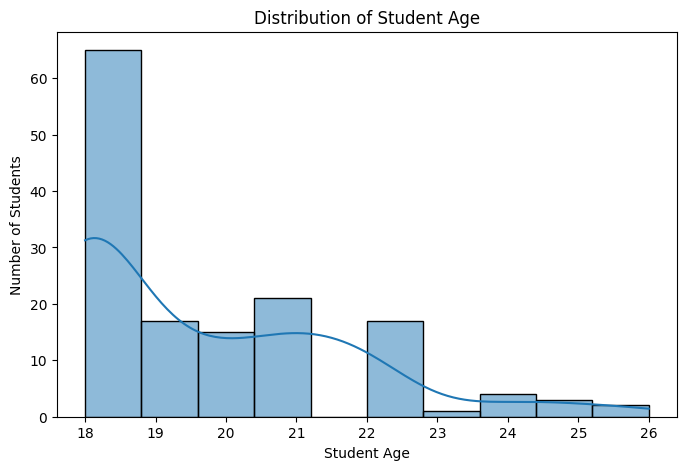

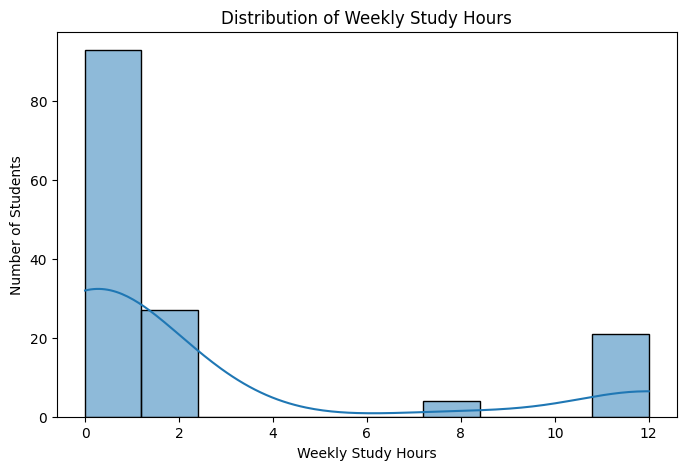

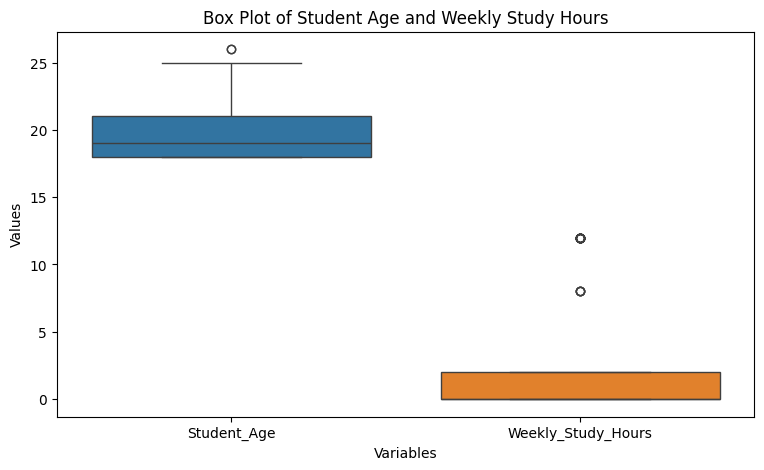

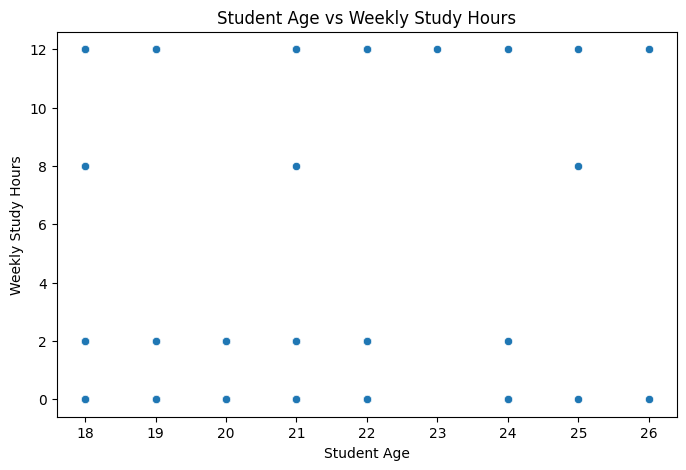

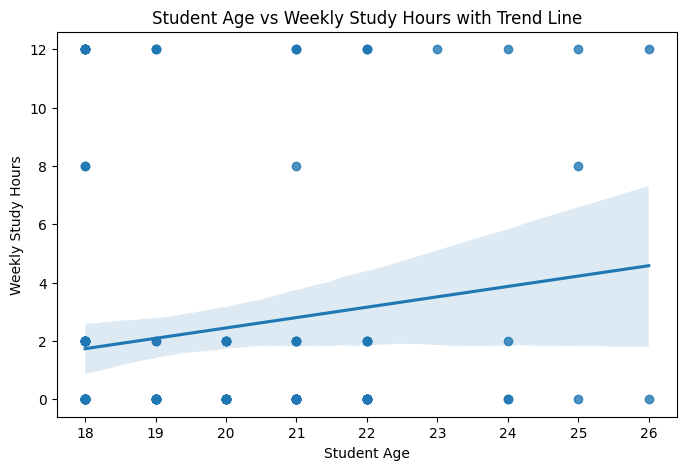

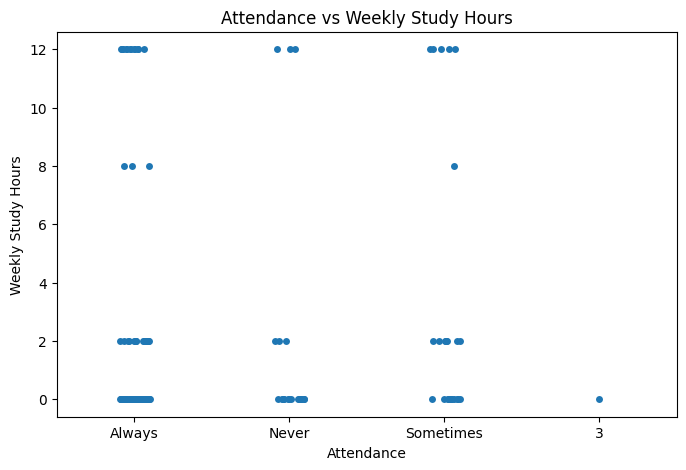

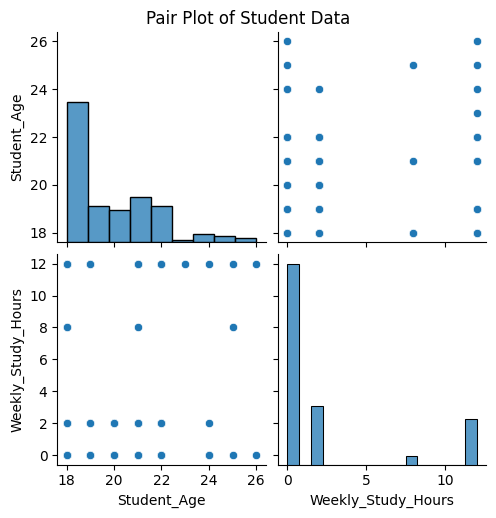


========== CORRELATION MATRIX ==========
                    Student_Age  Weekly_Study_Hours
Student_Age             1.00000             0.16673
Weekly_Study_Hours      0.16673             1.00000


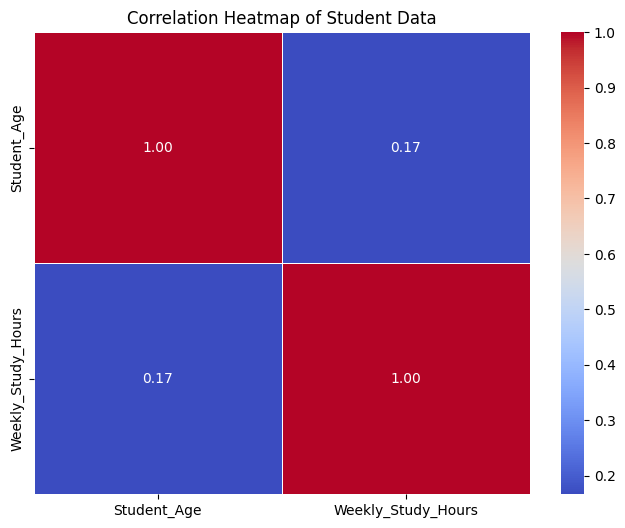

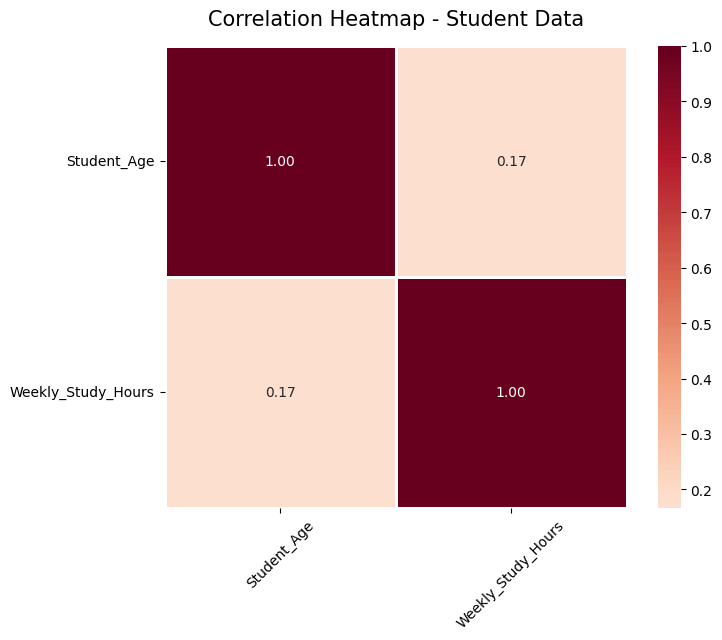


========== INDIVIDUAL CORRELATIONS ==========
Student_Age vs Weekly Study Hours: 0.1667301076128833

Data Visualization Experiment Completed Successfully!


In [2]:

# ============================================================
# DATA VISUALIZATION USING MATPLOTLIB AND SEABORN
# ============================================================

# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# 2. LOAD DATASET
# ============================================================

df = pd.read_csv("student.csv")

# Remove unnecessary automatically generated index column
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Display dataset
print("========== DATASET ==========")
print(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe())


# ============================================================
# 3. PREPARE DATA FOR VISUALIZATION
# ============================================================

# Select meaningful numerical columns
numeric_columns = ["Student_Age", "Weekly_Study_Hours"]

# Create numerical dataset
numeric_df = df[numeric_columns].apply(pd.to_numeric, errors="coerce")

# Remove missing values for numerical analysis
numeric_df = numeric_df.dropna()

# Select numerical columns for plotting
plot_df = df.loc[numeric_df.index].copy()


# ============================================================
# 4. HISTOGRAM OF STUDENT AGE
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=plot_df,
    x="Student_Age",
    bins=10,
    kde=True
)

plt.title("Distribution of Student Age")
plt.xlabel("Student Age")
plt.ylabel("Number of Students")
plt.show()


# ============================================================
# 5. HISTOGRAM OF WEEKLY STUDY HOURS
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=plot_df,
    x="Weekly_Study_Hours",
    bins=10,
    kde=True
)

plt.title("Distribution of Weekly Study Hours")
plt.xlabel("Weekly Study Hours")
plt.ylabel("Number of Students")
plt.show()


# ============================================================
# 6. BOX PLOT
# ============================================================

plt.figure(figsize=(9, 5))

sns.boxplot(data=numeric_df)

plt.title("Box Plot of Student Age and Weekly Study Hours")
plt.xlabel("Variables")
plt.ylabel("Values")
plt.show()


# ============================================================
# 7. SCATTER PLOT
# STUDENT AGE VS WEEKLY STUDY HOURS
# ============================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_df,
    x="Student_Age",
    y="Weekly_Study_Hours"
)

plt.title("Student Age vs Weekly Study Hours")
plt.xlabel("Student Age")
plt.ylabel("Weekly Study Hours")
plt.show()


# ============================================================
# 8. SCATTER PLOT WITH REGRESSION LINE
# ============================================================

plt.figure(figsize=(8, 5))

sns.regplot(
    data=plot_df,
    x="Student_Age",
    y="Weekly_Study_Hours"
)

plt.title("Student Age vs Weekly Study Hours with Trend Line")
plt.xlabel("Student Age")
plt.ylabel("Weekly Study Hours")
plt.show()


# ============================================================
# 9. ATTENDANCE VS WEEKLY STUDY HOURS
# ============================================================

plt.figure(figsize=(8, 5))

sns.stripplot(
    data=plot_df,
    x="Attendance",
    y="Weekly_Study_Hours",
    jitter=True
)

plt.title("Attendance vs Weekly Study Hours")
plt.xlabel("Attendance")
plt.ylabel("Weekly Study Hours")
plt.show()


# ============================================================
# 10. PAIR PLOT
# ============================================================

sns.pairplot(
    numeric_df,
    diag_kind="hist"
)

plt.suptitle(
    "Pair Plot of Student Data",
    y=1.02
)

plt.show()


# ============================================================
# 11. CORRELATION MATRIX
# ============================================================

correlation_matrix = numeric_df.corr()

print("\n========== CORRELATION MATRIX ==========")

print(correlation_matrix)


# ============================================================
# 12. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Data")
plt.show()


# ============================================================
# 13. BEAUTIFUL CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f",
    linewidths=1,
    square=True
)

plt.title(
    "Correlation Heatmap - Student Data",
    fontsize=15,
    pad=15
)

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()


# ============================================================
# 14. INDIVIDUAL CORRELATIONS
# ============================================================

print("\n========== INDIVIDUAL CORRELATIONS ==========")

for column in numeric_columns:
    if column != "Weekly_Study_Hours":
        correlation = numeric_df[column].corr(
            numeric_df["Weekly_Study_Hours"]
        )

        print(
            column,
            "vs Weekly Study Hours:",
            correlation
        )


# ============================================================
# END OF EXPERIMENT
# ============================================================

print("\nData Visualization Experiment Completed Successfully!")
